## PCA AC 20

This notebook computes historic time series for implied vols, fitting error, DLV vs a gixed NMS grid.



In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree
%aimport quantdata.widb.options_filter
%aimport quantdata.widb.timeseries
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.sanos.sanos_tools
%aimport quantdata.sanos.arbfree
%aimport quantdata.sanos.sanos
%aimport quantdata.dysanos.grid.interpolated
%aimport quantdata.dysanos.grid.torch_market
%aimport quantdata.dysanos.grid.torch_model
%aimport quantdata.dysanos.grid.torch_model_static
%aimport quantdata.dysanos.grid.torch_model_pca
%aimport quantdata.dysanos.grid.torch_gfx 
%aimport quantdata.dysanos.grid.torch_train 

from quantdata.dysanos.grid.torch_market import GridMarketDefinition, DateRange, PoolConfig, Context, date, GridConfig

grid_config     = GridConfig(grid_num_strikes=100)
grid_market_def = GridMarketDefinition( ticker="SPX", date_range=DateRange(start=date(2020, 1, 1), end=date(2025, 8, 30)), grid_config=grid_config )
market          = grid_market_def.load( pool_config = PoolConfig(num_workers=4, threading=False ), verbose=Context.all )
print(f"nms /done - found {len(market['dates'])} dates.")
    

nms /done - found 1412 dates.


00: Training 20-ac-SELU version 0.3 group 'sm25_100' for 100000 epochs on SPX for date range 2020-01-01_2025-08-30x
00: Using batches of 400 samples with learning rate 0.0001 and weight decay 1e-06.
01:   Model config: 20-ac-SELU@.sm25_100 0.3 0.25-smooth sample,mvsq=0.0001 nms=20,(-2.00,1.00) dlv=(0.01,3.00),fvol=(0.01,2.00) state=20@FF(d=2,w=100,a=SELU,b=True),lrn=FF(d=2,w=100,a=SELU,b=True)
01:   Grid config: nms,rg=(-2,1),nm=100,xp=(2.0,4.9,9.9,19.8,39.5,126.0,252.0);sth=0.25,mid=0.01,mxd=2,msqv=0.0001
01:   Mk Arb Free pre-processor: surface,mhs=0.0001,mw=0.10,mav=0.05,mik=5,mdn=0.0001,dC=0.001,dps=0.0001
01:   Options filter: nopt=1000,bdte=756,nmsat=(-5.0, 2.0),lvolu=1.0,loi=1.0,rmam=False,vegaSV=0.001,mxpp=10
01:   Raw day filter: bid=0.011
01:   Expiry filter: nat,eth=10,bth=4,mps=1e-06,miv=0.01,xiv=5.0
00: Preparing data set 20-ac-SELU version 0.3 on Env(prec=32,device=cuda,debug=False)... done; this took 3s.
00: Instantiating 20-ac-SELU version 0.3 on Env(prec=32,device=cuda

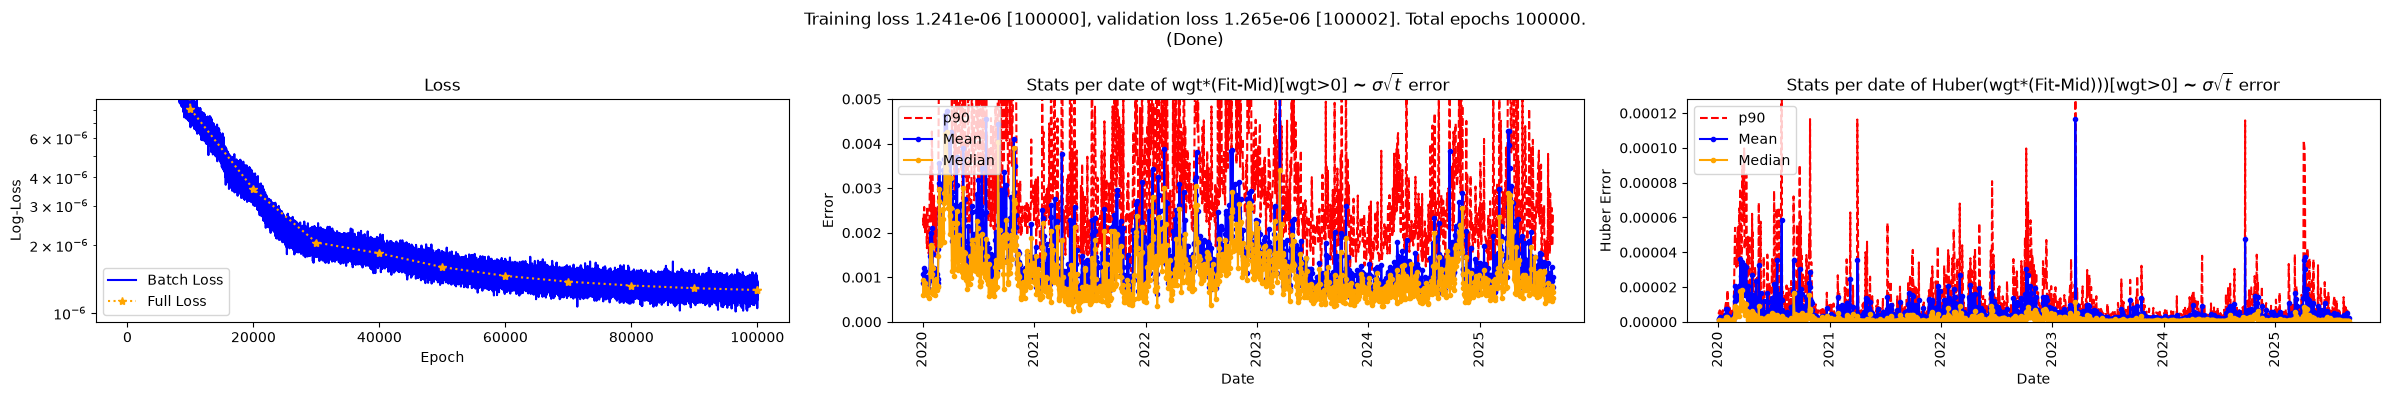

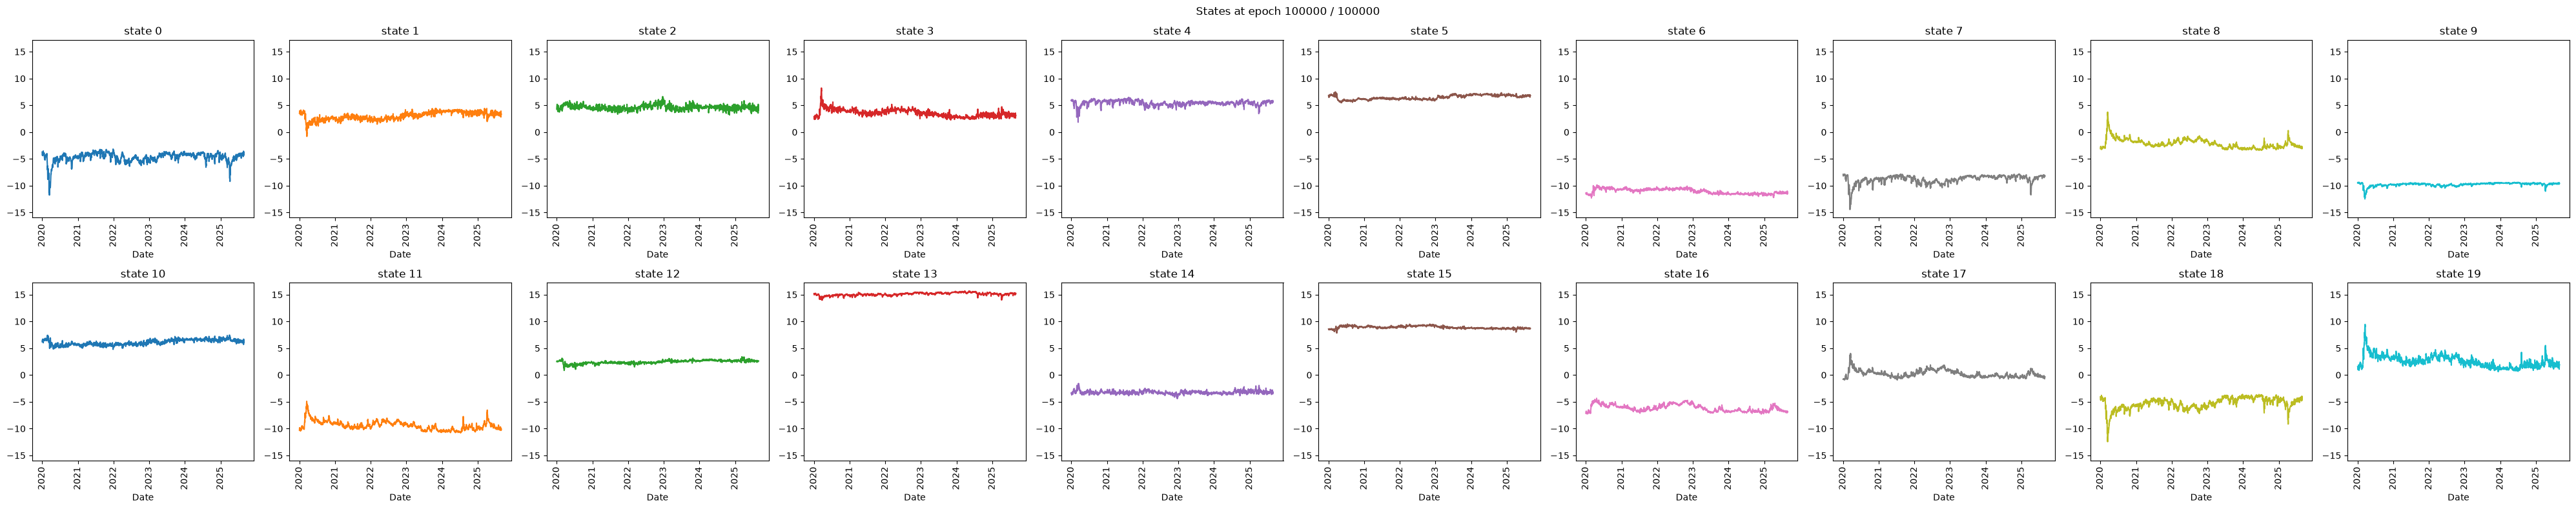

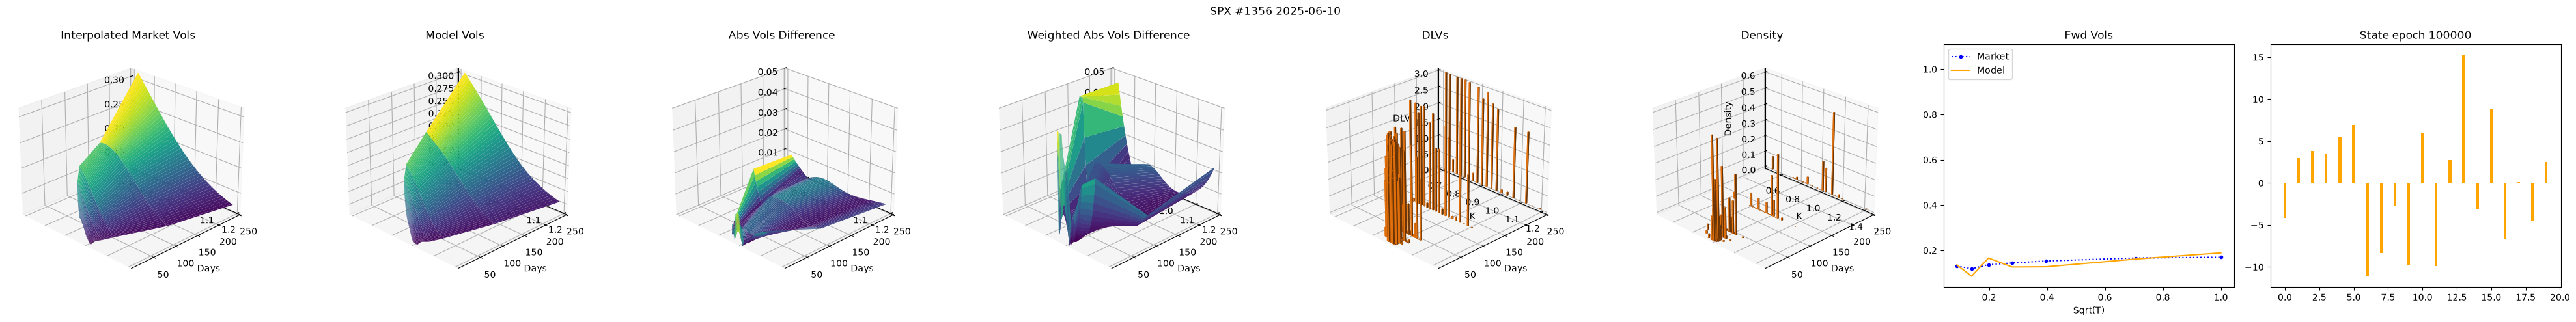

/home/hans/vqdata/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations


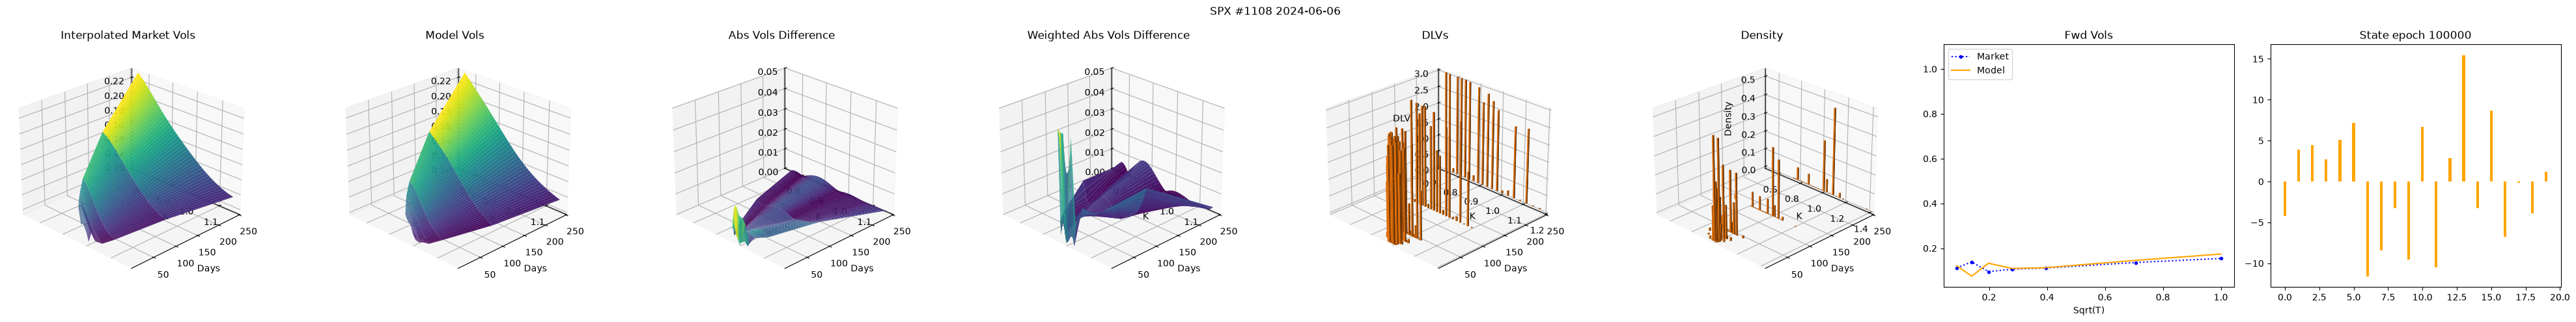

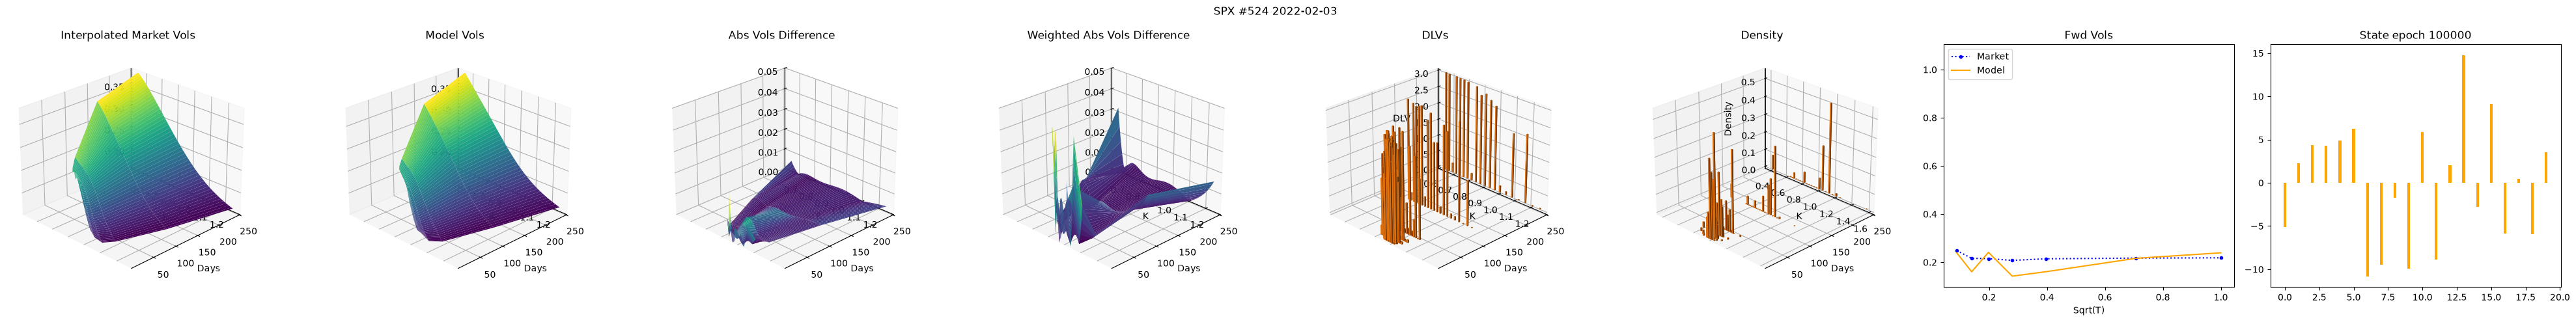

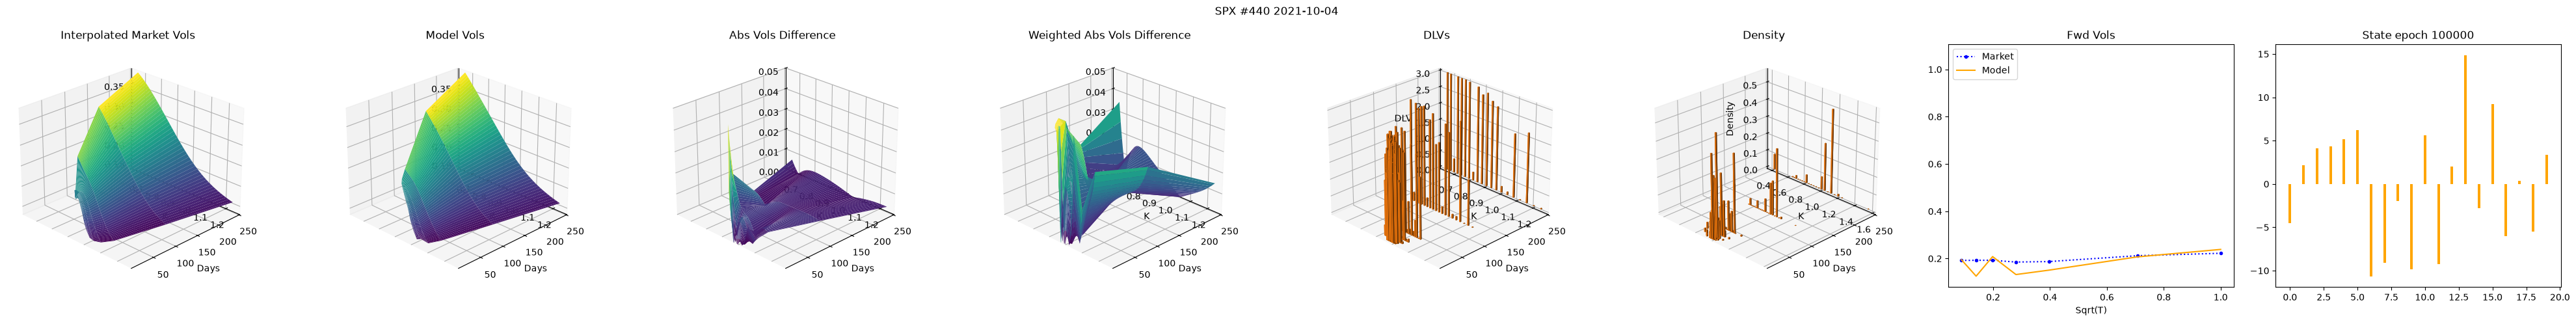

00: Model 20-ac-SELU version 0.3 group 'sm25_100' trained for 100000 epochs. Final training loss: 1.241e-06, valuation loss: 1.265e-06. This took 9s.
00: Checkpoint file is /home/hans/.dysanos_grid/sm25_100/20-ac-SELU f5aa8325.pt.
/done


In [2]:
from cdxcore.dynaplot import FigStore, colors_tableau, figure, m_o_m
from quantdata.pool import PoolConfig
from quantdata.dysanos.grid.torch_gfx import VizConfig
from quantdata.dysanos.grid.torch_train import train, TrainConfig
from quantdata.dysanos.grid.torch_model_static import BaseEnvironment, FeedForward, SanosCompressorConfig
import numpy as np

mdl_config = SanosCompressorConfig( 
    user_version="0.3",
    label="20-ac-SELU",
    group="sm25_100",
    smoothness = 0.25,
    num_state = 20, 
    state_config = FeedForward.Config(
        activation = "SELU",
        num_depth = 2,
        num_width = 100,
        use_bias = True,
    ),
    learn_config = FeedForward.Config(
        activation = "SELU",
        num_depth = 2,
        num_width = 100,
        use_bias = True,
    ),
)
viz_config = VizConfig( num_viz_dates=4 )
trn_config = TrainConfig( num_epochs=100_000, lr=1E-4, final_lr=1E-6, weight_decay=1e-6, batch_size=400, compile=True, epoch_interval=10000 )
r, model, tdata = train( market, mdl_config=mdl_config, trn_config=trn_config, viz_config=viz_config )
print("/done")

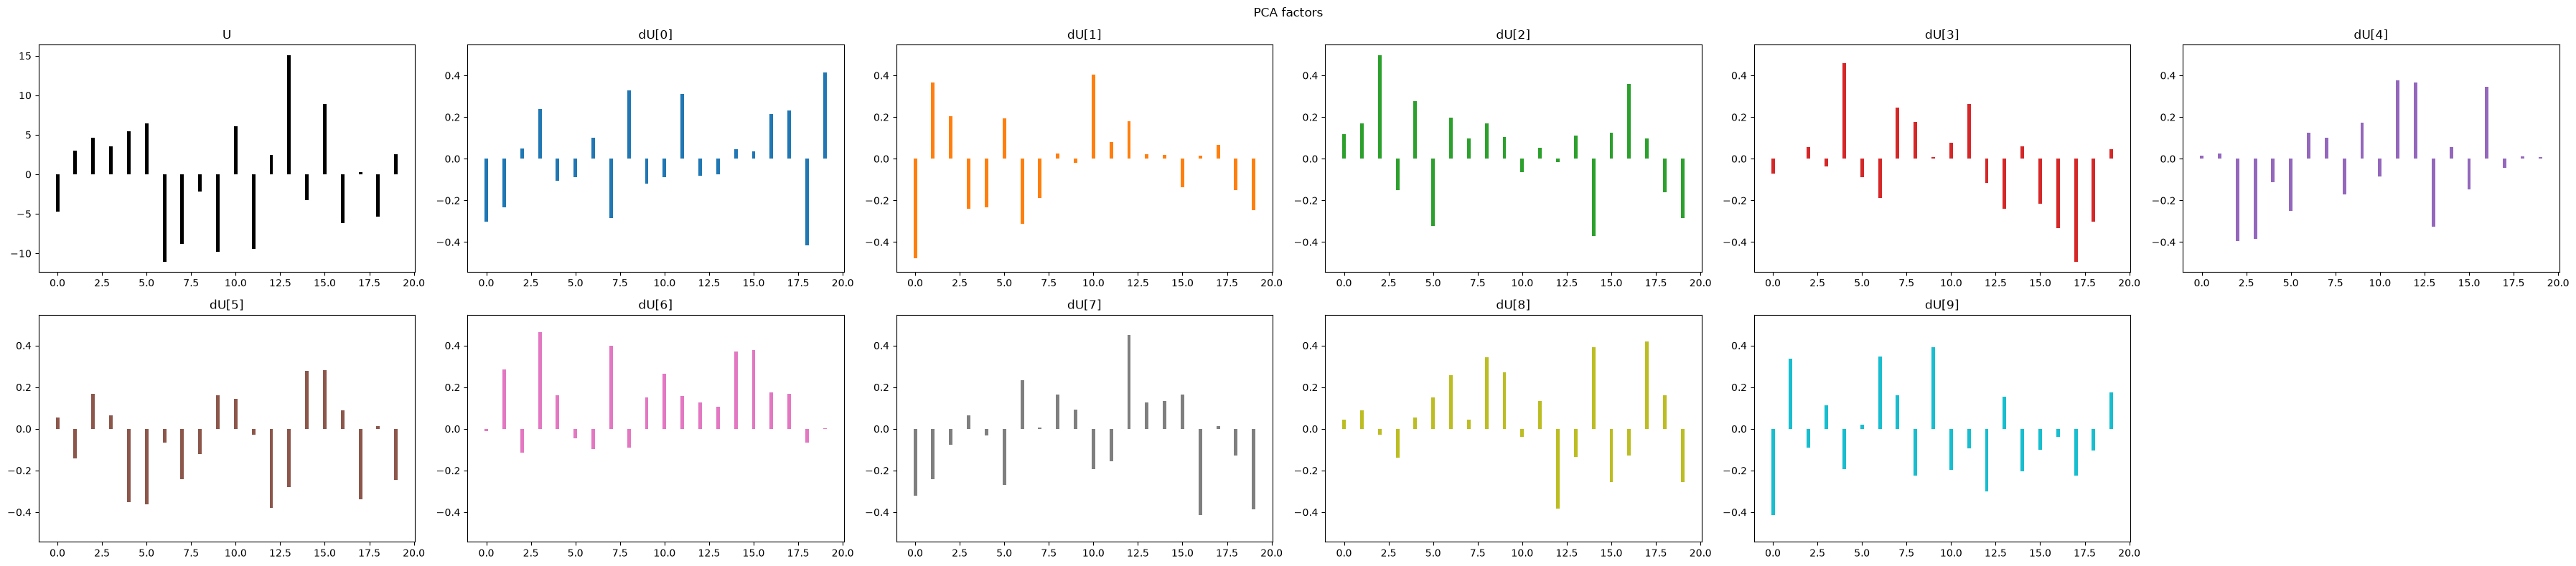

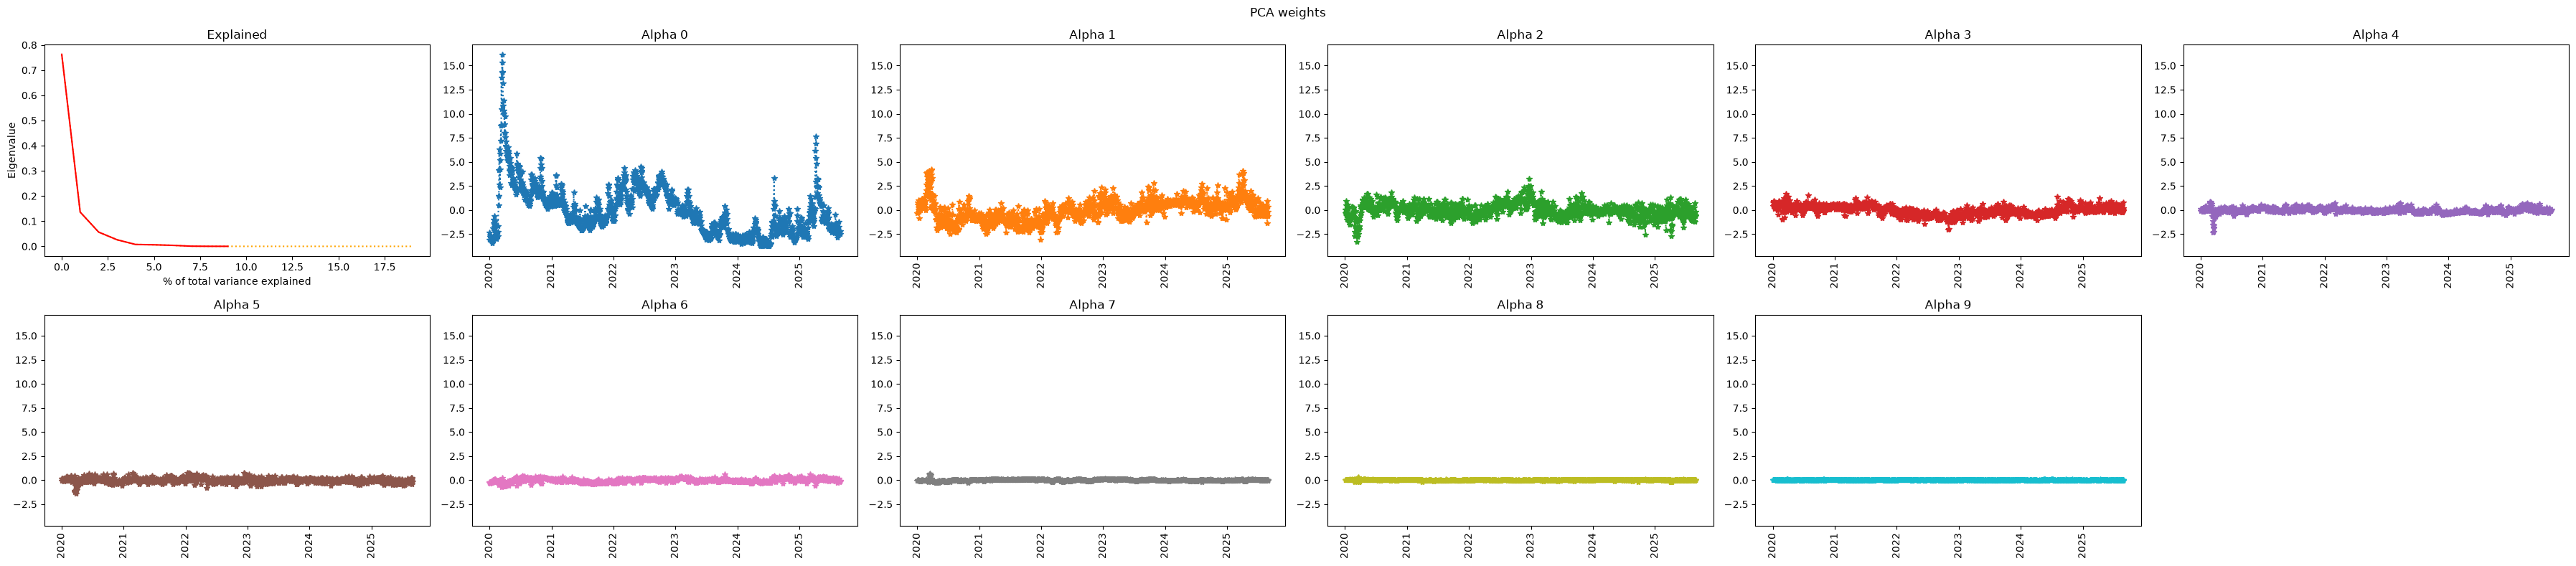

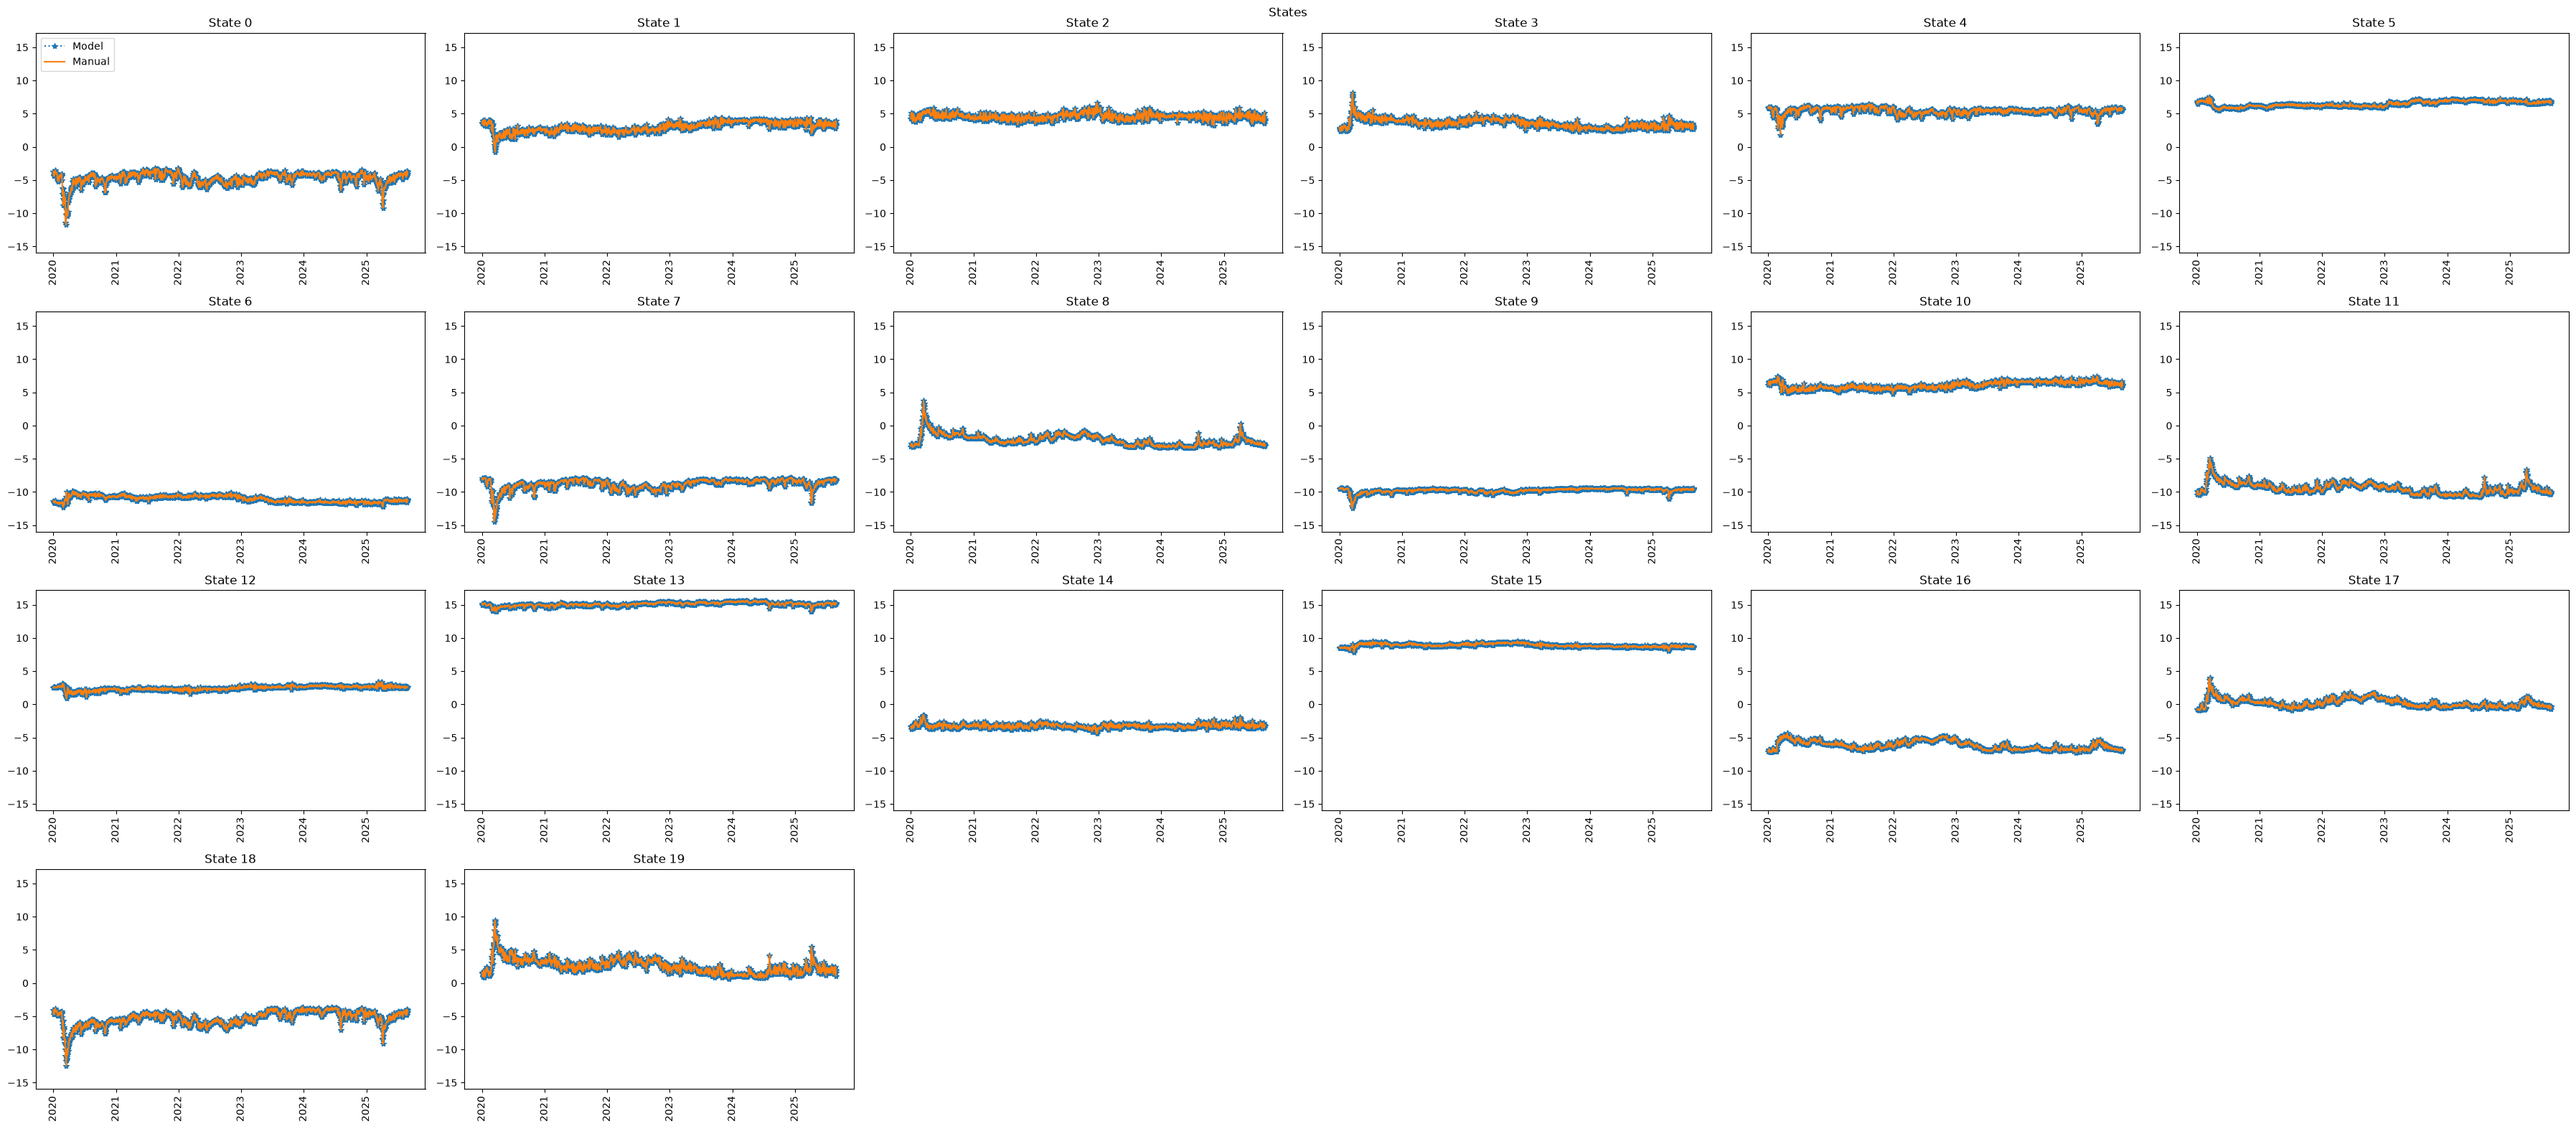

In [3]:
from cdxcore.dynaplot import figure, colors_tableau, m_o_m
import numpy as np

def plot_stuff(*,draw_pca_factors=True, draw_pca_alpha=True, draw_states=True):
    dates = market.dates
    ld = model(tdata, training=False)
    ld = { k: v.detach().cpu().numpy() for k, v in ld.items() if not v is None }

    T         = len(dates)
    state     = ld['state']
    num_state = state.shape[-1]
    num_alpha = 10
    
    # manual PCA
    def pca_():
        mu0    = np.mean(state, axis=0, keepdims=True)
        Xc     = state - mu0
        U, SD, Vt = np.linalg.svd(Xc, full_matrices=False)
        mdu   = Vt[:num_alpha]               # shape (K, M), orthonormal rows
        assert mdu.shape == (num_alpha,num_state)
        alpha2 = U[:, :num_alpha] * SD[:num_alpha]     # shape (T, num_alpha)
        ev        = SD**2
        return alpha2, np.concatenate( [mu0, mdu], axis=0 ), ev
    malpha, mu_du, mev = pca_()
    
    if draw_pca_factors:
        def draw(label, u_du):
            with figure(label + " factors", row_size=4, col_size=6, columns=6 ) as fig:
                ax_ = None
                colors = colors_tableau()
                for i in range(u_du.shape[0]):
                    ax = fig.add_subplot("U" if i==0 else f"dU[{i-1}]")
                    ax.bar( np.arange(u_du.shape[1]), u_du[i,:], width=0.2, color="black" if i==0 else next(colors))
                    if i>0:
                        if not ax_ is None:
                            ax.sharey(ax_)
                        else:
                            ax_ = ax
                ax_.set_ylim( m_o_m( u_du[1:,:] ) )
        draw("PCA", mu_du)
    
    if draw_pca_alpha:
        def draw( label, alpha ):
            with figure(label + " weights", row_size=4, col_size=6, columns=6 ) as fig:
                ax = fig.add_subplot("Explained")
                ax.plot( np.arange(0,len(mev)), mev/np.sum(mev), ":", color="orange", label="All")
                ax.plot( np.arange(0,num_alpha), mev[:num_alpha]/np.sum(mev), "-", color="red",label=f"First {num_alpha}")
                ax.set_xlabel("% of total variance explained")
                ax.set_ylabel("Eigenvalue")
                
                ax_ = None
                colors = colors_tableau()
                for i in range(alpha.shape[1]):
                    ax = fig.add_subplot(f"Alpha {i}")
                    ax.plot( dates, alpha[:,i], "*:", label="Model", color=next(colors))
                    ax.tick_params(axis="x", labelrotation=90)
                    if not ax_ is None:
                        ax.sharey(ax_)
                    else:
                        ax_ = ax
                ax_.set_ylim( m_o_m(alpha) )
        draw("PCA", malpha)

    if draw_states:
        with figure("States", row_size=4, col_size=6, columns=6 ) as fig:
            ax_ = None
            colors = colors_tableau()
            for i in range(state.shape[1]):
                ax = fig.add_subplot(f"State {i}")
                ax.plot( dates, state[:,i], "*:", label="Model")
                ax.plot( dates, state[:,i], label="Manual")
                ax.tick_params(axis="x", labelrotation=90)
                ax.legend(loc="upper left") if i==0 else None
                if not ax_ is None:
                    ax.sharey(ax_)
                else:
                    ax_ = ax
            ax_.set_ylim( m_o_m(state) )




plot_stuff()




In [4]:
from dataclasses import dataclass
from cdxcore.err import verify_inp
from cdxcore.verbose import Context
from quantdata.dysanos.grid.torch_simulator import 

@dataclass(frozen=True)
class SamplerConfig:
    num_alpha : int|float|None = 10   # number of PCA factors as integer or float for % vriance cut off
    rescale_var : bool = True
    
    

class SampleGenerator(object):
    def __init__(self, market, model, tdata, *, config : SamplerConfig = SamplerConfig(), verbose : Context = Context.all ):
        self.market = market
        self.tdata  = tdata
        self.model  = model
        self.model_output = model(tdata, training=False)
        self.config = config

        # PCA
        # ---
        T         = len(market.dates)
        state     = self.model_output['state']
        num_state = state.shape[-1]
        self.u0   = np.mean(state, axis=0, keepdims=True)
        Xc        = state - self.u0
        U, SD, Vt = np.linalg.svd(Xc, full_matrices=False)
        assert len(SD) == num_state, "Internal shape error"
        ev        = SD**2
        total_var = np.sum(ev)
        self.vars_explained = np.cumsum(ev)/total_var

        if config.num_alpha is None or config.num_alpha == -1:
            self.num_alpha = num_state 
        elif isinstance( config.num_alpha, int ):
            verify_inp( config.num_alpha > 0 and config.num_alpha <= num_state, lambda : f"'num_alpha' must be positive and if it is an integer, less than the number of states ({num_states}). Found {config.num_alpha}" )#
            self.num_alpha = config.num_alpha
        else:
            verify_inp( isinstance( config.num_alpha, float ), lambda : f"'num_alpha' must be a float or int, found {type(config.num_alpha)}" )
            verify_inp( config.num_alpha > 0. and config.num_alpha <= 1., lambda : f"'num_alpha' as float must be positive and not exceed 1. Found {config.num_alpha}")
            if config.num_alpha >= 1.:
                self.num_alpha = num_state
            elif self.num_alpha.num_alpha <= self.vars_explained[0]:
                num_alpha = 1
            else:
                self.num_alpha = min( np.searchsorted(self.vars_explained, config.num_alpha), num+_state )
                assert num_alpha >= 0, "Internal error"
                
        self.du            =    Vt[:num_alpha]               
        self.alpha         = U[:, :num_alpha] * SD[:num_alpha]
        self.var_explained = self.vars_explained[num_alpha-1]
        
        assert self.u0.shape == (num_state,), "Internal error"
        assert self.du.shape == (num_alpha,num_state), "Internal error"
        assert self.alpha.shape == (T,num_alpha), "Internal error"
        assert self.vars_explained.shape == (num_state,), "Internal error"

        verbose.write( lamnda : f"Model {model.qualified_label}: using {self.num_alpha} factors for {num_state} states over {T} dates. The {self.num_alpha} factors explain {self.var_explained:.0%}" of variance.")

        

        
        
def sample_smoothed(X, n_samples, bandwidth=0.1, rng=None):
    """
    X: shape (M, N), empirical samples
    bandwidth: noise scale relative to empirical covariance
    """
    rng = np.random.default_rng(rng)

    M, N = X.shape
    idx = rng.integers(0, M, size=n_samples)

    base = X[idx]

    cov = np.cov(X, rowvar=False)
    L = np.linalg.cholesky(cov + 1e-12 * np.eye(N))

    noise = rng.normal(size=(n_samples, N)) @ L.T
    return base + bandwidth * noise
    def sample():
        

SyntaxError: unterminated string literal (detected at line 58) (449802561.py, line 58)